# 03 The van Cittert–Zernike Theorem

**Series:** Physics of the CHARA Array (Mount Wilson Observatory)
**Topic T3:** what an interferometer actually measures, and how that links to the picture of the source.

Notebook 02 ended with a result: fringe contrast (visibility) changes with baseline, and the pattern depends on the source's shape. This notebook gives the general rule.

**The rule in one sentence:** each baseline lays a striped pattern across the sky, and the fringe it measures says how well the source lines up with those stripes. In maths terms, the measured visibility is one Fourier component of the source's image. This is the **van Cittert–Zernike theorem**. Radio interferometers such as the VLA, ALMA and the Event Horizon Telescope rely on the same theorem.

1. Fringes on the sky act as a ruler.
2. Each baseline samples one point of the source's 2D Fourier transform.
3. Small sources need long baselines.
4. The visibility also has a phase, which tells where the light is.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import PowerNorm
from scipy.special import j1
from scipy.ndimage import gaussian_filter
from ipywidgets import interact, FloatSlider, Dropdown

RAD_TO_MAS = 180 / np.pi * 3600 * 1000  # radians -> milliarcseconds
MAS_TO_RAD = 1 / RAD_TO_MAS

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
SLIDER_STYLE = {"handle_color": BLUE}  # visible knob on white backgrounds
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "lines.linewidth": 2,
})

WAVELENGTH = 1.65e-6          # H band, metres
CHARA_MIN, CHARA_MAX = 34, 331  # baseline range, metres

## A sky to observe

The cell below builds small test images of the sky, 16 mas across. Each one is a simple shape that a real star or star system can have:

- **Point:** an unresolved star.
- **Binary:** two stars, the second one half as bright.
- **Uniform disk:** a star's surface seen face-on.
- **Gaussian blob:** a fuzzy cloud, such as dust around a star.
- **Elongated star:** a rapidly spinning star flattened into an oval.

`size` sets the separation (binary), the diameter (disk) or the width (blob, oval).

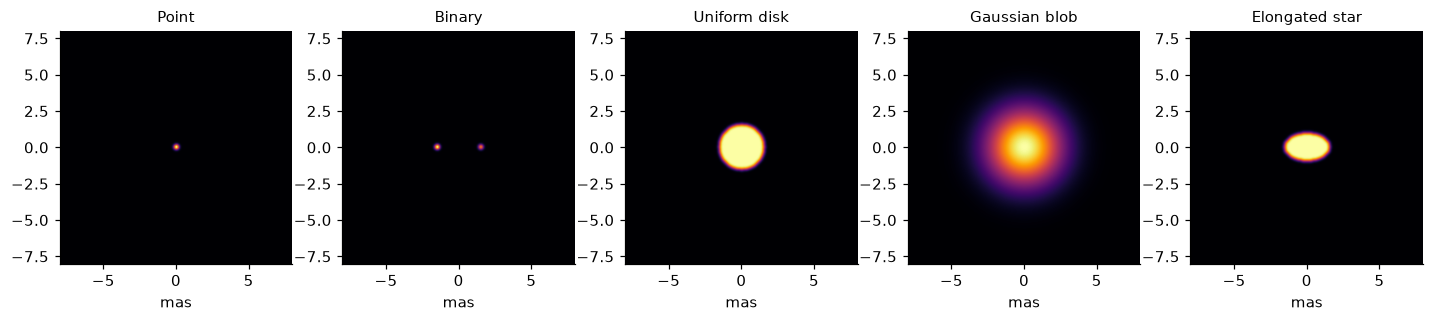

In [2]:
N_SKY = 256
FOV_MAS = 16.0
PIX_MAS = FOV_MAS / N_SKY
SKY_AXIS = (np.arange(N_SKY) - N_SKY / 2) * PIX_MAS
SKY_X, SKY_Y = np.meshgrid(SKY_AXIS, SKY_AXIS)
SOURCES = ["Point", "Binary", "Uniform disk", "Gaussian blob", "Elongated star"]


def make_sky(kind, size_mas):
    sky = np.zeros((N_SKY, N_SKY))
    centre = N_SKY // 2
    if kind == "Point":
        sky[centre, centre] = 1.0
    elif kind == "Binary":
        offset = int(round(size_mas / PIX_MAS))
        sky[centre, centre - offset // 2] = 1.0
        sky[centre, centre - offset // 2 + offset] = 0.5
    elif kind == "Uniform disk":
        sky[np.hypot(SKY_X, SKY_Y) <= size_mas / 2] = 1.0
    elif kind == "Gaussian blob":
        sigma = size_mas / 2.355  # size is the full width at half maximum
        sky = np.exp(-(SKY_X ** 2 + SKY_Y ** 2) / (2 * sigma ** 2))
    elif kind == "Elongated star":
        a, b = size_mas / 2, 0.6 * size_mas / 2  # long axis along x
        sky[(SKY_X / a) ** 2 + (SKY_Y / b) ** 2 <= 1] = 1.0
    return sky / sky.sum()


def visibility(sky, u, v):
    # Complex visibility at spatial frequency (u, v) in cycles per radian.
    x = SKY_X * MAS_TO_RAD
    y = SKY_Y * MAS_TO_RAD
    lit = sky > 0
    phase = -2 * np.pi * (np.multiply.outer(u, x[lit]) + np.multiply.outer(v, y[lit]))
    return (sky[lit] * np.exp(1j * phase)).sum(axis=-1)


def visibility_ew(sky, u):
    # East-west baselines only: collapse the sky onto the x axis first (much faster).
    profile = sky.sum(axis=0)
    x = SKY_AXIS * MAS_TO_RAD
    return (profile * np.exp(-2j * np.pi * np.multiply.outer(u, x))).sum(axis=-1)


def for_display(sky):
    # Blur slightly so single-pixel stars are visible, scale to 0..1.
    shown = gaussian_filter(sky, 1.5)
    return shown / shown.max()


fig, axes = plt.subplots(1, 5, figsize=(13, 2.8))
for ax, kind in zip(axes, SOURCES):
    ax.imshow(for_display(make_sky(kind, 3.0)), extent=[-8, 8, -8, 8], origin="lower",
              cmap="inferno", norm=PowerNorm(0.5))
    ax.set_title(kind, fontsize=10)
    ax.set_xlabel("mas")
    ax.grid(False)
plt.tight_layout()
plt.show()

## 1. Fringes on the sky are a ruler

From notebook 02: a star at angle $x$ from the pointing centre arrives with an extra path $B\,x$. So the fringe it produces is shifted by $B\,x/\lambda$ wavelengths. Looked at from the sky, the interferometer paints **stripes** across the field: bright where light arrives in step, dark where it arrives half a wavelength out. The stripe spacing is $\lambda/B$, the same spacing as in notebook 01.

The detector does not see an image. It sees one number: all the source's light **multiplied by the stripes** and added up. As the delay line scans the OPD, the stripes slide sideways and that number goes up and down. That swing is the fringe.

- If the source fits inside one bright stripe, it brightens and dims all together: **high visibility**.
- If the source spans bright and dark stripes, the parts cancel: **low visibility**.

The top row shows the source, the stripes, and their product. The bottom left is the detected signal as the stripes slide. The bottom right is visibility against baseline, with the current baseline marked.

In [3]:
@interact(
    kind=Dropdown(options=SOURCES, value="Uniform disk", description="Source"),
    size_mas=FloatSlider(value=3.0, min=0.2, max=8.0, step=0.1, description="size (mas)",
                         continuous_update=False, style=SLIDER_STYLE),
    baseline_m=FloatSlider(value=100, min=CHARA_MIN, max=CHARA_MAX, step=1,
                           description="B (m)", continuous_update=False,
                           style=SLIDER_STYLE),
)
def show_sky_ruler(kind, size_mas, baseline_m):
    sky = make_sky(kind, size_mas)
    u = baseline_m / WAVELENGTH
    stripes = 1 + np.cos(2 * np.pi * u * SKY_X * MAS_TO_RAD)
    vis = visibility_ew(sky, u)

    fig = plt.figure(figsize=(12, 7.5))
    gs = GridSpec(2, 6, figure=fig, height_ratios=[1, 0.9])
    extent = [-8, 8, -8, 8]
    panels = [
        (for_display(sky), "Source on the sky", "inferno"),
        (stripes, f"Fringe stripes, spacing λ/B = {WAVELENGTH / baseline_m * RAD_TO_MAS:.2f} mas", "gray"),
        (for_display(sky) * stripes / 2, "Source × stripes (what is summed)", "inferno"),
    ]
    for i, (image, title, cmap) in enumerate(panels):
        ax = fig.add_subplot(gs[0, 2 * i:2 * i + 2])
        norm = PowerNorm(0.5, vmin=0, vmax=1) if cmap == "inferno" else None
        ax.imshow(image, extent=extent, origin="lower", cmap=cmap, norm=norm)
        ax.set_title(title, fontsize=9)
        ax.set_xlabel("mas")
        ax.grid(False)

    ax_sig = fig.add_subplot(gs[1, 0:3])
    opd_um = np.linspace(0, 3 * WAVELENGTH * 1e6, 400)
    signal = 1 + np.abs(vis) * np.cos(2 * np.pi * opd_um / (WAVELENGTH * 1e6) + np.angle(vis))
    ax_sig.plot(opd_um, signal, color=BLUE)
    ax_sig.set_ylim(0, 2.1)
    ax_sig.set_xlabel("OPD as the stripes slide (µm)")
    ax_sig.set_ylabel("Detected signal")
    ax_sig.set_title(f"Fringe, visibility V = {np.abs(vis):.2f}", fontsize=10)

    ax_v = fig.add_subplot(gs[1, 3:6])
    baselines = np.linspace(0, 400, 300)
    curve = np.abs(visibility_ew(sky, baselines / WAVELENGTH))
    ax_v.plot(baselines, curve, color=BLUE)
    ax_v.axvspan(CHARA_MIN, CHARA_MAX, color=ORANGE, alpha=0.1, label="CHARA baselines")
    ax_v.scatter([baseline_m], [np.abs(vis)], s=80, color=ORANGE, zorder=3)
    ax_v.set_ylim(0, 1.05)
    ax_v.set_xlabel("Baseline (m)")
    ax_v.set_ylabel("Visibility |V|")
    ax_v.set_title("Visibility vs baseline (east-west)", fontsize=10)
    ax_v.legend(fontsize=8, loc="upper right")
    plt.tight_layout()
    plt.show()

interactive(children=(Dropdown(description='Source', index=2, options=('Point', 'Binary', 'Uniform disk', 'Gau…

**Try this:**

- **Point:** every baseline gives $V = 1$. The point always sits inside one stripe.
- **Uniform disk, 3 mas:** slide the baseline up. When the stripe spacing gets close to the disk size, the disk covers a bright and a dark stripe and the fringe flattens.
- **Binary:** watch the stars fall on bright and dark stripes as the baseline changes. This is the repeating visibility pattern from notebook 02.
- **Gaussian blob:** the visibility fades smoothly to zero and never comes back. Fuzzy edges have no fine detail.

## 2. Each baseline samples one Fourier component

"Multiply by a cosine and add up" is exactly what a **Fourier transform** does. A Fourier transform breaks an image into stripe patterns of every spacing and direction, and records how much of each the image contains. So the theorem says:

$$V(u, v) = \frac{\iint I(x, y)\, e^{-2\pi i (u x + v y)}\, dx\, dy}{\iint I(x, y)\, dx\, dy}, \qquad u = \frac{B_x}{\lambda},\; v = \frac{B_y}{\lambda}$$

- $I(x, y)$ is the source's brightness on the sky.
- $(u, v)$ is the baseline measured in wavelengths, east-west and north-south. Astronomers call this the **uv plane**.
- Baseline **length** sets the stripe spacing. Baseline **direction** sets the stripe orientation.

The right-hand panel below is the full 2D Fourier transform of the source, labelled in metres of baseline. One baseline measures one point of it (plus its mirror point, since the source is real-valued). The ring marks the lengths CHARA can reach.

In [4]:
PAD = 2048  # zero-pad the sky so the uv plane is finely sampled
UV_STEP_M = WAVELENGTH / (PAD * PIX_MAS * MAS_TO_RAD)  # metres of baseline per uv pixel
UV_AXIS_M = (np.arange(PAD) - PAD / 2) * UV_STEP_M


def uv_amplitude(sky):
    padded = np.zeros((PAD, PAD))
    start = PAD // 2 - N_SKY // 2
    padded[start:start + N_SKY, start:start + N_SKY] = sky
    ft = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(padded)))
    return np.abs(ft)


@interact(
    kind=Dropdown(options=SOURCES, value="Elongated star", description="Source"),
    size_mas=FloatSlider(value=3.0, min=0.2, max=8.0, step=0.1, description="size (mas)",
                         continuous_update=False, style=SLIDER_STYLE),
    baseline_m=FloatSlider(value=200, min=CHARA_MIN, max=CHARA_MAX, step=1,
                           description="B (m)", continuous_update=False,
                           style=SLIDER_STYLE),
    angle_deg=FloatSlider(value=0, min=0, max=180, step=5, description="angle (°)",
                          continuous_update=False, style=SLIDER_STYLE),
)
def show_uv_plane(kind, size_mas, baseline_m, angle_deg):
    sky = make_sky(kind, size_mas)
    angle = np.radians(angle_deg)
    bx, by = baseline_m * np.cos(angle), baseline_m * np.sin(angle)
    vis = visibility(sky, np.array(bx / WAVELENGTH), np.array(by / WAVELENGTH))
    stripes = 1 + np.cos(2 * np.pi * (bx * SKY_X + by * SKY_Y) * MAS_TO_RAD / WAVELENGTH)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5))
    ax1.imshow(stripes, extent=[-8, 8, -8, 8], origin="lower", cmap="gray", alpha=0.35)
    shown = for_display(sky)
    ax1.imshow(np.ma.masked_less(shown, 1e-3), extent=[-8, 8, -8, 8],
               origin="lower", cmap="inferno", norm=PowerNorm(0.5, vmin=0, vmax=1))
    ax1.set_title(f"Source with the stripes of this baseline\n|V| = {np.abs(vis):.2f}",
                  fontsize=10)
    ax1.set_xlabel("mas (east-west)")
    ax1.set_ylabel("mas (north-south)")
    ax1.grid(False)

    view = 400
    keep = np.abs(UV_AXIS_M) <= view
    amp = uv_amplitude(sky)[np.ix_(keep, keep)]
    ax2.imshow(amp, extent=[UV_AXIS_M[keep][0], UV_AXIS_M[keep][-1]] * 2, origin="lower",
               cmap="inferno", norm=PowerNorm(0.5, vmin=0, vmax=1))
    for radius in (CHARA_MIN, CHARA_MAX):
        ax2.add_patch(plt.Circle((0, 0), radius, fill=False, color=AQUA, lw=1.2, ls="--"))
    ax2.scatter([bx, -bx], [by, -by], s=90, color=AQUA, edgecolor="white", zorder=3,
                label="this baseline and its mirror")
    ax2.set_xlim(-view, view)
    ax2.set_ylim(-view, view)
    ax2.set_title("|Fourier transform| of the source (the uv plane)", fontsize=10)
    ax2.set_xlabel("Baseline east-west (m)")
    ax2.set_ylabel("Baseline north-south (m)")
    ax2.legend(fontsize=8, loc="upper right")
    ax2.grid(False)
    plt.tight_layout()
    plt.show()

interactive(children=(Dropdown(description='Source', index=4, options=('Point', 'Binary', 'Uniform disk', 'Gau…

**Try this:**

- **Elongated star:** rotate the baseline. Along the long axis (0°) the visibility drops fastest, because the oval is widest that way. The uv plane is an oval too, but turned 90°: **long on the sky means short in the uv plane**.
- **Binary:** the uv plane is striped. The stripes are the repeating visibility pattern from notebook 02, now in 2D.
- **Point:** the uv plane is flat and bright everywhere.

One baseline gives one point. To learn a source's shape you need many points spread over the uv plane. CHARA gets them from 15 telescope pairs and from Earth's rotation, which turns each baseline across the sky. That is topic T5.

## 3. Small sources need long baselines

The Fourier transform has one property that drives the whole design of CHARA: **size on the sky and spread in the uv plane are inverses.** Halve the source and its visibility curve stretches to twice the baseline.

For a uniform disk of angular diameter $\theta$, the visibility has a closed form (the same Bessel function as the Airy pattern in notebook 01):

$$V(B) = \left|\frac{2 J_1(x)}{x}\right|, \qquad x = \frac{\pi\, \theta\, B}{\lambda}$$

The first zero falls at $B = 1.22\,\lambda/\theta$.

In [5]:
@interact(
    diameter_mas=FloatSlider(value=3.3, min=0.2, max=10.0, step=0.1, description="θ (mas)",
                             continuous_update=False, style=SLIDER_STYLE),
    wavelength_um=FloatSlider(value=1.65, min=0.5, max=2.2, step=0.05, description="λ (µm)",
                              continuous_update=False, style=SLIDER_STYLE),
)
def show_disk_size(diameter_mas, wavelength_um):
    lam = wavelength_um * 1e-6
    theta = diameter_mas * MAS_TO_RAD
    baselines = np.linspace(1e-3, 600, 1200)
    x = np.pi * theta * baselines / lam
    vis = np.abs(2 * j1(x) / x)
    first_null = 1.22 * lam / theta
    v_longest = np.abs(2 * j1(np.pi * theta * CHARA_MAX / lam) / (np.pi * theta * CHARA_MAX / lam))

    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.plot(baselines, vis, color=BLUE)
    ax.axvspan(CHARA_MIN, CHARA_MAX, color=ORANGE, alpha=0.1, label="CHARA baselines")
    if first_null <= baselines[-1]:
        ax.axvline(first_null, color=GREY, ls="--", lw=1,
                   label=f"first zero at {first_null:.0f} m")
    ax.scatter([CHARA_MAX], [v_longest], s=80, color=ORANGE, zorder=3,
               label=f"V at 331 m = {v_longest:.2f}")
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Baseline (m)")
    ax.set_ylabel("Visibility |V|")
    ax.set_title(f"Uniform disk, θ = {diameter_mas:.1f} mas, λ = {wavelength_um:.2f} µm")
    ax.legend(fontsize=8, loc="upper right")
    plt.tight_layout()
    plt.show()

    print(f"First zero of the visibility: B = {first_null:.0f} m")

interactive(children=(FloatSlider(value=3.3, continuous_update=False, description='θ (mas)', max=10.0, min=0.2…

**Try this:**

- **Vega (3.3 mas) in H band:** the first zero is at about 125 m, well inside CHARA's range.
- **A 0.5 mas star:** the first zero is at about 830 m, far beyond CHARA. But at 331 m the visibility has already fallen to about 0.72. With good calibration, that drop alone measures the diameter.

This is the meaning of the "λ/2B resolution" quoted in notebook 01. A star of angular size $\lambda/2B$ lowers the visibility on the longest baseline enough to measure. You do not need to reach the first zero.

## 4. Visibility has a phase too

So far the plots showed $|V|$, the fringe contrast. $V$ is a complex number, and its **phase** is where the fringe sits, i.e. how far it is shifted along the OPD axis. The phase tells you **where** the light is:

- Moving the whole source sideways shifts every fringe. The phase changes, the contrast does not.
- A **symmetric** source (point, disk, equal binary) has a phase of 0° or 180° once centred.
- An **asymmetric** source, such as a binary with unequal stars, has a phase that varies smoothly with baseline. You cannot tell which star is on which side without it.

The cell below uses a binary along the east-west direction.

In [6]:
@interact(
    separation_mas=FloatSlider(value=2.0, min=0.2, max=5.0, step=0.1, description="sep (mas)",
                               continuous_update=False, style=SLIDER_STYLE),
    flux_ratio=FloatSlider(value=0.5, min=0.0, max=1.0, step=0.05, description="B/A flux",
                           continuous_update=False, style=SLIDER_STYLE),
    shift_mas=FloatSlider(value=0.0, min=-2.0, max=2.0, step=0.1, description="shift (mas)",
                          continuous_update=False, style=SLIDER_STYLE),
)
def show_binary_phase(separation_mas, flux_ratio, shift_mas):
    baselines = np.linspace(0, 400, 1000)
    u = baselines / WAVELENGTH
    x_a = shift_mas * MAS_TO_RAD
    x_b = (shift_mas + separation_mas) * MAS_TO_RAD
    vis = (np.exp(-2j * np.pi * u * x_a) + flux_ratio * np.exp(-2j * np.pi * u * x_b)) / (1 + flux_ratio)

    fig = plt.figure(figsize=(12, 6.5))
    gs = GridSpec(2, 3, figure=fig)
    ax_sky = fig.add_subplot(gs[:, 0])
    ax_sky.scatter([shift_mas], [0], s=300, color=BLUE, label="star A")
    if flux_ratio > 0:
        ax_sky.scatter([shift_mas + separation_mas], [0], s=300 * flux_ratio, color=ORANGE,
                       label="star B")
    ax_sky.axvline(0, color=GREY, lw=1, ls="--", label="pointing centre")
    ax_sky.set_xlim(-3, 7)
    ax_sky.set_ylim(-3, 3)
    ax_sky.set_aspect("equal")
    ax_sky.set_xlabel("mas (east-west)")
    ax_sky.set_title("Sky", fontsize=10)
    ax_sky.legend(fontsize=8, loc="upper right")

    ax_amp = fig.add_subplot(gs[0, 1:])
    ax_amp.plot(baselines, np.abs(vis), color=BLUE)
    ax_amp.axvspan(CHARA_MIN, CHARA_MAX, color=ORANGE, alpha=0.1)
    ax_amp.set_ylim(0, 1.05)
    ax_amp.set_ylabel("|V| (contrast)")
    ax_amp.set_title("Amplitude and phase vs baseline", fontsize=10)

    ax_ph = fig.add_subplot(gs[1, 1:], sharex=ax_amp)
    ax_ph.scatter(baselines, np.degrees(np.angle(vis)), s=2, color=BLUE)
    ax_ph.axvspan(CHARA_MIN, CHARA_MAX, color=ORANGE, alpha=0.1)
    ax_ph.set_ylim(-185, 185)
    ax_ph.set_yticks([-180, -90, 0, 90, 180])
    ax_ph.set_xlabel("Baseline (m)")
    ax_ph.set_ylabel("Phase (degrees)")
    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='sep (mas)', max=5.0, min=0.…

**Try this:**

- Move **shift**. The amplitude curve does not change at all. The phase gains a steady slope.
- Set **B/A flux** to 1 and **shift** to −1 (the pair centred on the pointing centre). The phase only takes the values 0° and 180°.
- Lower the flux ratio again. The phase wanders smoothly, and that wandering is what records which side the faint star is on.

**A catch:** the atmosphere adds a random, fast-changing delay to each telescope, which scrambles the measured phase. Interferometers recover part of it with a trick called **closure phase**. That is topic T7.

## Summary

| Idea | What it means |
|---|---|
| Fringes on the sky | Each baseline paints stripes of spacing $\lambda/B$, oriented along the baseline |
| Visibility | Source × stripes, summed. Contrast is $|V|$, shift is the phase |
| van Cittert–Zernike | $V(u, v)$ is the Fourier transform of the sky image at $u = B_x/\lambda$, $v = B_y/\lambda$ |
| Size vs baseline | Small on the sky = spread out in the uv plane. Smaller sources need longer baselines |
| Phase | Records where the light is. Needed for asymmetric sources |

1. An interferometer does not take a picture. Each baseline measures one Fourier component of the picture.
2. Baseline length picks the stripe spacing, baseline direction picks their orientation.
3. Small structure lives at long baselines. CHARA's 331 m reaches sizes of about 0.5 mas in H band.
4. Amplitude says how big, phase says where.

**Next:** T4 uses this to measure real stellar diameters, including limb darkening and fitting real CHARA data.